# From a physical circuit to "this is a T gate": a walkthrough

> **In short.**
> * **The question.** A $T$ gate cannot be applied directly to a qubit protected by the Steane code. It is *injected*: a special state is prepared in a second protected block, coupled to the first by CNOTs and measured, and a correction is applied depending on the result. Does this 20-qubit program really apply $T$ to the protected qubit, in every run?
> * **The answer.** Yes, $T$ in every run (Part F). The tool also finds the code after every stage (Part D) and what each block does (Part E), from the gates alone. Of four deliberate changes (Part G), forgetting the correction or applying it in the wrong runs makes the result wrong; $S$ instead of $S^\dagger$ is still right, up to a Pauli the computer only has to remember; and a check wired to the wrong qubit leaves the result right but no longer protected.
> * **How to read the pictures.** Part A draws the code and the trick. From Part B on, the program is a ZX-diagram: lines are qubits, time runs left to right, green and red dots are Z- and X-spiders, and a CNOT is a green dot joined to a red dot.

This notebook takes one small fault-tolerant protocol, **injecting a T gate into a qubit protected by the Steane code**, and asks the three questions of the paper:

1. **Which error-correcting code** are the qubits in, at each point of the program?
2. **What does each part of the program do** to the protected ("logical") qubit?
3. **Does the program do the right thing in every run**, whatever the measurements return?

The tool answers all three starting from the gates alone. Nothing about the code is typed in.

You do not need to know error correction to follow it. **Part A** explains the few ideas the rest uses, with pictures. Parts B to F run the tool, and Part G breaks the program on purpose three times to show what the tool reports.

| part | what happens |
|---|---|
| A | the ideas: qubits, Pauli operators, codes, stabilizers, the T gate, injection |
| B | level 1: the program as it runs on hardware, stage by stage |
| C | level 2: grouping the stages into blocks and saying what each block is for |
| D | question 1: the code after every stage |
| E | question 2: what each block does to the logical qubits |
| F | question 3: does the whole program always implement T? |
| G | three broken versions, and what the table says about each |

## Part A. The ideas you need

### A.1 Qubits, Pauli operators, measurements

A **qubit** is the quantum version of a bit. Three operations on one qubit appear everywhere in error correction:

* **X** swaps 0 and 1 (a "bit flip");
* **Z** leaves 0 alone and puts a minus sign on 1 (a "phase flip");
* **Y** does both (up to a factor).

These three are the **Pauli operators**. On several qubits we write a string: `XXIZ` means X on qubit 0, X on qubit 1, nothing (`I`) on qubit 2 and Z on qubit 3.

**Measuring** a qubit returns 0 or 1. In this notebook, measurement results are not numbers but **symbols** `c[0]`, `c[1]`, …. The tool never simulates a single run: it reasons about every possible result at once.

### A.2 Why codes, and the Steane code

Physical qubits make errors. A **code** spreads one logical qubit over several physical qubits so that errors can be *noticed*. The **Steane code** uses seven qubits, drawn below as a triangle with three coloured faces.

It is described by **stabilizers**: checks that give +1 on every correctly encoded state. The Steane code has six. For each face there is "X on its four qubits" and "Z on its four qubits". An error on one qubit flips some of the checks, which is how it is detected.

The **logical X** (flip the encoded bit) is X on all seven qubits. Multiplying it by a stabilizer changes nothing on encoded states, so X on qubits 3, 5, 6 does the same job. The logical Z is similar with Z.

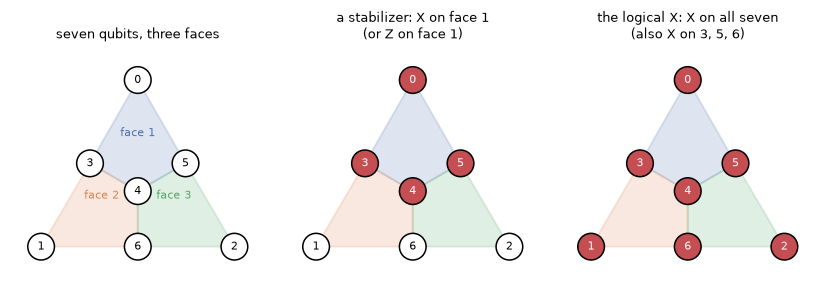

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from teaching_figures import (steane_code_figure, t_gadget_figure, protocol_figure,
                              sandwich_figure, levels_figure, paulis_figure)
steane_code_figure();

### A.3 Checks are measured with helper qubits

A check such as "Z on qubits 0, 3, 4, 5" is measured with a **helper qubit**: CNOTs from the four qubits into the helper, then the helper is measured. The result, 0 or 1, says whether the check is +1 or −1. For "X on a face", the helper is sandwiched between two H gates and the CNOTs point the other way. You will see exactly these gates in stage 3 below.

### A.4 Transversal gates, and why T is the hard one

Some logical gates are easy: apply one physical gate to each qubit of the block, qubit by qubit. These are called **transversal**. They cannot spread one error to two qubits of the same block. For the Steane code:

* CNOT from qubit *i* of one block to qubit *i* of another is a **logical CNOT**;
* H on all seven qubits is a **logical H**;
* S on all seven qubits is a **logical S†** (note the dagger; Part G shows why that matters).

The **T gate** has no transversal version in this code, and a quantum computer needs it: without T, everything can be simulated efficiently on a classical computer. The standard trick is to **inject** it.

### A.5 T-gate injection

1. Prepare a special "magic" state T|+⟩ on a second block.
2. Apply a CNOT from the data block to the magic block.
3. Measure the magic block. Call the result *m*.

If *m* = 0, the data now carries T|ψ⟩. If *m* = 1, it carries T†|ψ⟩, and applying **S** repairs it, because S·T† = T. So the program must look at *m* and *decide*: a **classically controlled correction**.

In the Steane code the magic block is measured by measuring all seven qubits. The logical result *m* is the **parity** (XOR) of the seven outcomes. The tool will find exactly this.

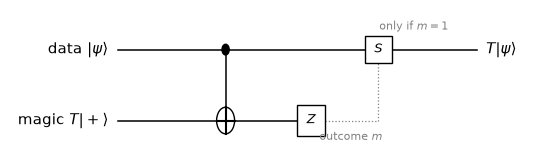

In [2]:
t_gadget_figure();

## Part B. Level 1: the program as physical gates

This is **all the tool gets**: gates on 20 qubits, cut into stages.

* qubits 0–6: the **data block** (qubit 3 carries the input state);
* qubits 7–13: the **magic block**;
* qubits 14–19: **helper qubits** for the checks.

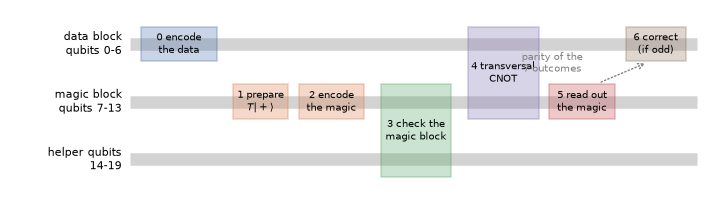

In [3]:
protocol_figure();

The encoder of the Steane code is a short circuit. It copies the input (on qubit 3) onto qubits 5 and 6, puts qubits 0, 1, 2 in superposition with H, and spreads each of them over one face with CNOTs. The three faces are the lists in `CHECKS`.

The last stage uses `ParityControlled`: "apply this gate if the XOR of these outcomes is 1". This is the classical control of Part A.5. The correction is S† on every data qubit, because S† on all seven qubits is the logical S. The arguments `correction` and `z_check` exist only for Part G.

In [4]:
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, T, Measurement
from zxqec.qprogram import QProgram, ParityControlled

CHECKS = [(0, 3, 4, 5), (1, 3, 4, 6), (2, 4, 5, 6)]      # the three faces
DATA, MAGIC, HELP = list(range(7)), list(range(7, 14)), list(range(14, 20))
N, BITS = 20, 13
READOUT = ['c[{}]'.format(6 + i) for i in range(7)]     # outcomes of the 7 magic-block measurements

def encoder(block):
    """Steane encoder: the input sits on block[3], the other six qubits start in |0>."""
    gates = [CNOT(block[3], block[5]), CNOT(block[3], block[6])]
    gates += [HAD(block[i]) for i in (0, 1, 2)]
    for i, face in zip((0, 1, 2), CHECKS):
        gates += [CNOT(block[i], block[j]) for j in face if j != i]
    return gates

def stage(gates):
    c = Circuit(N, bit_amount=BITS)
    for g in gates:
        c.add_gate(g)
    return c

def injection_program(correction='S^dag', z_check=None):
    """The protocol of this notebook. correction=None leaves the last stage out;
    z_check replaces the first Z check (a way to wire a check wrongly, for Part G)."""
    z_checks = [z_check or CHECKS[0]] + CHECKS[1:]
    p = QProgram(N, bits=BITS, initial_states={q: '0' for q in DATA + MAGIC + HELP if q != 3})
    # stage 0: encode the data block; its qubit 3 is the open input
    p.add_circuit(stage(encoder(DATA)), name='encode data')
    # stage 1: the magic state T|+> on the middle qubit of the magic block
    p.add_circuit(stage([HAD(MAGIC[3]), T(MAGIC[3])]), name='prepare T|+>')
    # stage 2: encode it
    p.add_circuit(stage(encoder(MAGIC)), name='encode magic')
    # stage 3: one round of the six checks on the magic block, with helper qubits 14..19
    gates = []
    for k, face in enumerate(CHECKS):                      # X checks: H, CNOTs out of the helper, H
        h = HELP[k]
        gates += [HAD(h)] + [CNOT(h, MAGIC[q]) for q in face] + [HAD(h), Measurement(h, k)]
    for k, face in enumerate(z_checks):                    # Z checks: CNOTs into the helper
        h = HELP[3 + k]
        gates += [CNOT(MAGIC[q], h) for q in face] + [Measurement(h, 3 + k)]
    p.add_circuit(stage(gates), name='check magic')
    # stage 4: transversal CNOT, data qubit i -> magic qubit i
    p.add_circuit(stage([CNOT(DATA[i], MAGIC[i]) for i in range(7)]), name='transversal CNOT')
    # stage 5: measure the magic block; outcomes c[6] .. c[12]
    p.add_circuit(stage([Measurement(MAGIC[i], 6 + i) for i in range(7)]), name='read out magic')
    # stage 6: if the parity of the readout is 1, apply the correction on every data qubit
    if correction:
        p.add_circuit(stage([ParityControlled(correction, DATA[i], READOUT) for i in range(7)]),
                      name='correct')
    return p

p = injection_program()
for s in range(p.num_stages):
    print(s, p.stage(s))

0 encode data
1 prepare T|+>
2 encode magic
3 check magic
4 transversal CNOT
5 read out magic
6 correct


## Part C. Level 2: saying what each block is for

A programmer thinks in blocks: "this part encodes", "this part checks". `group_stages` groups stages into blocks and gives each one a **role**. The tool then checks each block against its role.

Grouping is **recursive**. Below we build two levels:

* a **fine** level, with one block per step of Part A.5;
* a **coarse** level, where everything from "prepare" to "correct" becomes one block, *inject T*.

The roles are ordinary strings. The ones the tool knows how to check are listed in `zxqec.qprogram.levels.ROLES`.

Level 6 (6 blocks):
  Block 0 'encode data' (encoder): [encode data]
  Block 1 'prepare magic' (state preparation): [prepare T|+>, encode magic]
  Block 2 'check magic' (syndrome extraction): [check magic]
  Block 3 'transversal CNOT' (logical gate): [transversal CNOT]
  Block 4 'read out magic' (logical measurement): [read out magic]
  Block 5 'correct' (correction): [correct]

Level 7 (2 blocks):
  Block 0 'encode data' (encoder): [encode data]
  Block 1 'inject T' (injection): [prepare T|+>, encode magic, check magic, transversal CNOT, read out magic, correct]


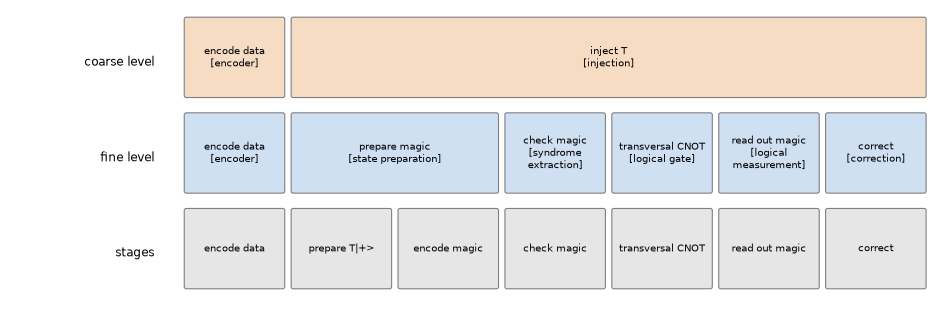

In [5]:
fine = p.group_stages([
    (0, 0, 'encode data',       'encoder'),
    (1, 2, 'prepare magic',     'state preparation'),
    (3, 3, 'check magic',       'syndrome extraction'),
    (4, 4, 'transversal CNOT',  'logical gate'),
    (5, 5, 'read out magic',    'logical measurement'),
    (6, 6, 'correct',           'correction'),
])
coarse = p.level_up(fine, 1, 5, name='inject T', role='injection')
print(p.describe_level(fine)); print(); print(p.describe_level(coarse))
levels_figure(p, [fine, coarse], names=['fine level', 'coarse level']);

The same program as a ZX-diagram: time runs left to right (one column per gate), one horizontal line per qubit, and the blocks of the fine level are shaded. Every gate is a small cluster of green (Z) and red (X) spiders. Measurement outcomes appear as phases such as `c[6]` on the spiders.

You do not need to read the diagram. The point is that the tool works on this object, not on a description of the code.

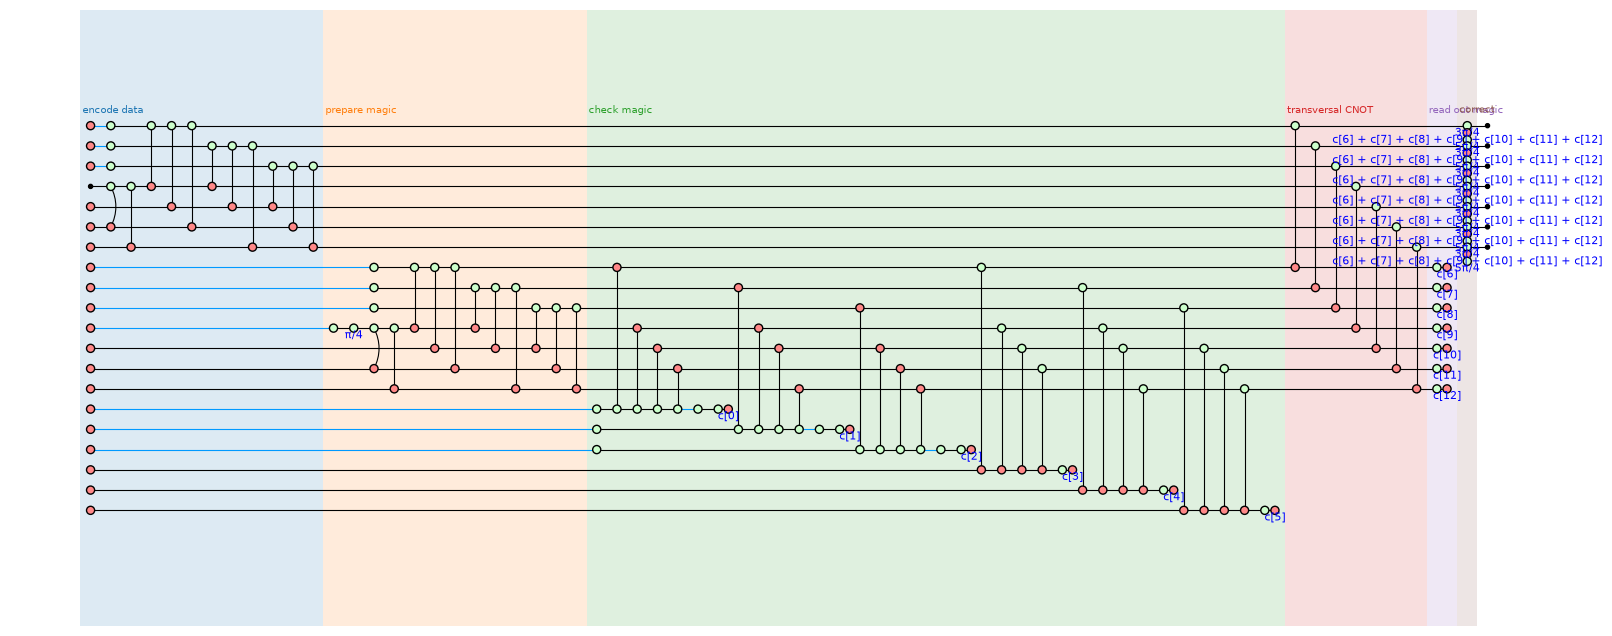

In [6]:
from zxqec.spacetime import draw_program
draw_program(p, level=fine, figsize=(20, 8), show_time=False, time_axis=False)

## Part D. Question 1: which code?

`p.code_at(s)` cuts the program after stage *s*. The cut diagram maps the program's input to the qubits alive at that point, and the tool reads the code directly off it. It first brings the diagram to a normal form with two layers: green spiders on the input side, red spiders on the output side (paper §4). Then:

* each green spider **not** attached to an input is an **X stabilizer**, on the qubits it is wired to;
* each green spider attached to an input is a **logical X**;
* the Z stabilizers are the Z strings that agree with all of those.

Below, `[[n, k, d]]` means *n* physical qubits, *k* logical qubits, and **distance** *d*: the smallest number of qubits an undetected error must touch. For the Steane code, d = 3.

In [7]:
for s in range(p.num_stages):
    code = p.code_at(s)
    parts = ["[[{},{},{}]] on qubits {}{}".format(*b.parameters, list(b.qubits),
             "  <- holds a non-Clifford state" if b.non_clifford else "") for b in code.blocks()]
    print("after stage {} ({}):".format(s, p.stage(s)))
    for part in parts:
        print("    " + part)

after stage 0 (encode data):
    [[7,1,3]] on qubits [0, 1, 2, 3, 4, 5, 6]


after stage 1 (prepare T|+>):
    [[7,1,3]] on qubits [0, 1, 2, 3, 4, 5, 6]
    [[1,1,1]] on qubits [10]  <- holds a non-Clifford state
after stage 2 (encode magic):
    [[7,1,3]] on qubits [0, 1, 2, 3, 4, 5, 6]
    [[7,1,3]] on qubits [7, 8, 9, 10, 11, 12, 13]  <- holds a non-Clifford state
after stage 3 (check magic):
    [[7,1,3]] on qubits [0, 1, 2, 3, 4, 5, 6]
    [[7,1,3]] on qubits [7, 8, 9, 10, 11, 12, 13]  <- holds a non-Clifford state
after stage 4 (transversal CNOT):
    [[7,1,3]] on qubits [0, 1, 2, 3, 4, 5, 6]  <- holds a non-Clifford state
    [[7,1,3]] on qubits [7, 8, 9, 10, 11, 12, 13]  <- holds a non-Clifford state
after stage 5 (read out magic):
    [[7,1,3]] on qubits [0, 1, 2, 3, 4, 5, 6]  <- holds a non-Clifford state
after stage 6 (correct):
    [[7,1,3]] on qubits [0, 1, 2, 3, 4, 5, 6]  <- holds a non-Clifford state


Reading the list:

* After stage 0 the data block is in a **[[7,1,3]]** code: the Steane code, found from the encoder circuit alone.
* After stage 1 the magic qubit (qubit 10) holds T|+⟩, a state that is not a stabilizer state. The tool marks this "non-Clifford".
* After stage 2 the magic block is a second Steane code, holding that non-Clifford logical state.
* After stage 5 the magic block has been measured, so only the data block is left.
* The data block is marked non-Clifford from stage 4 on, because the CNOT has entangled it with the magic state.

Here are the stabilizers the tool found for the data block, drawn on the triangle:

[[7, 1, 3]] CSS code on qubits 0, 1, 2, 3, 4, 5, 6
    stabilizer +XXXIXII
    stabilizer +XXIIIXX
    stabilizer +XIXXIIX
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X XXIXIII   logical Z ZZIZIII


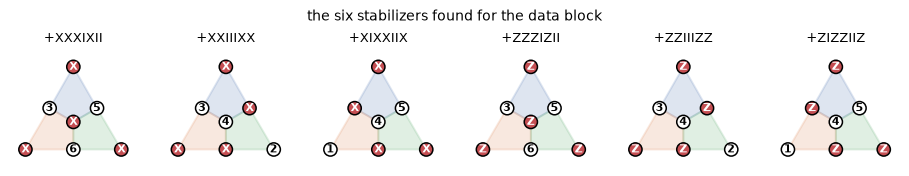

In [8]:
data = p.code_at(0).data()
print(data)
paulis_figure(data.stabilizers, data.qubits, "the six stabilizers found for the data block");

These are **not the three faces** we drew in Part A, but they describe the same code. Any three independent X checks do, and the tool lists the lightest ones. For example, `XXXIXII` (X on 0, 1, 2, 4) is the product of all three faces. The next cell asks the tool whether each face, and the logical operator X on all seven qubits, is in what it found.

In [9]:
def pauli(letter, qubits, n=7):
    return ''.join(letter if q in qubits else 'I' for q in range(n))

for face in CHECKS:
    print("X on face", face, "is a stabilizer:", data.contains(pauli('X', face)),
          "| Z on it:", data.contains(pauli('Z', face)))
print("X on all seven is a stabilizer:", data.contains('XXXXXXX'),
      " <- it is the logical X, not a stabilizer")
print("logical X found by the tool:", data.logical_x[0], "   logical Z:", data.logical_z[0])

X on face (0, 3, 4, 5) is a stabilizer: True | Z on it: True
X on face (1, 3, 4, 6) is a stabilizer: True | Z on it: True
X on face (2, 4, 5, 6) is a stabilizer: True | Z on it: True
X on all seven is a stabilizer: False  <- it is the logical X, not a stabilizer
logical X found by the tool: +XXIXIII    logical Z: +ZZIZIII


The signs in front of the stabilizers are all `+`: the data block is prepared by a circuit, not by measuring. In a protocol that *prepares* a code by measuring its checks, the tool writes the measurement outcome as the sign. For example, in the fold-transversal H case study it prints `(-1)^(c[2]) IXXIIIIII`: the check X₂X₃ was measured and returned `c[2]`.

## Part E. Question 2: what does each block do?

To find what a block does to the logical qubits, the tool builds three pieces and joins them:

1. the **ideal encoder** of the code *before* the block (from Part D);
2. the block itself, with all its gates and measurements;
3. the **ideal decoder** of the code *after* the block.

Then it simplifies the result. What is left acts only on logical qubits. That is the block's **logical action**, still with the measurement outcomes as symbols.

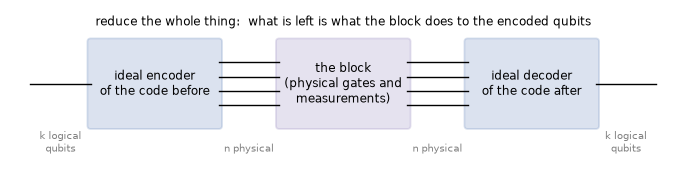

In [10]:
sandwich_figure();

In [11]:
fine_summary = p.summary(fine)
print(fine_summary.table())

block               role                 code before            code after             logical action                                    every run?  checks
0 encode data       encoder              [[1,1,1]]              [[7,1,3]]              I                                                 yes         ok
1 prepare magic     state preparation    [[7,1,3]]              [[7,1,3]] + [[7,1,3]]  I on qubits 0-6 (x) prepares T|+> on qubits 7-13  yes         ok
2 check magic       syndrome extraction  [[7,1,3]] + [[7,1,3]]  [[7,1,3]] + [[7,1,3]]  I                                                 yes         ok
3 transversal CNOT  logical gate         [[7,1,3]] + [[7,1,3]]  [[7,1,3]] + [[7,1,3]]  CNOT(0->1)                                        yes         ok
4 read out magic    logical measurement  [[7,1,3]] + [[7,1,3]]  [[7,1,3]]              I on qubits 0-6 (x) Z measurement on qubits 7-13  yes         ok
5 correct           correction           [[7,1,3]]              [[7,1,3]]           

Row by row:

| block | what the tool says | in words |
|---|---|---|
| encode data | `I` | encoding does not change the logical state; it only protects it |
| prepare magic | `I on qubits 0-6 (x) prepares T\|+> on qubits 7-13` | the data is untouched, and a logical T\|+⟩ appears in the second code |
| check magic | `I` | a round of checks changes nothing, which is exactly what checks should do |
| transversal CNOT | `CNOT(0->1)` | seven physical CNOTs are one logical CNOT from data to magic |
| read out magic | `I on qubits 0-6 (x) Z measurement on qubits 7-13` | measuring the seven qubits measures the logical Z of the magic block |
| correct | `I / S` | in some runs nothing happens, in others logical S |

The `correct` row says "no" under *every run?*. That is expected for a correction: it is *meant* to depend on the outcomes. The detailed view shows the condition:

In [12]:
print(fine_summary.blocks[5].describe())

Block 5 'correct' (correction) -- stages 6
  code before: [[7,1,3]] on qubits 0,1,2,3,4,5,6 (non-Clifford logical content)
  code after:  [[7,1,3]] on qubits 0,1,2,3,4,5,6 (non-Clifford logical content)
  logical action: not deterministic: the operation depends on the outcomes (I when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 0; S when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 1)
  ok      applies I when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 0; S when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 1


The condition is exactly the one from Part A.5: **S when the parity of the seven readout outcomes is 1**. Note also that seven physical S† gates came out as one *logical S*.

The simplified diagram of a block can be drawn. Here is the transversal CNOT block: seven physical CNOTs became one logical CNOT, a green spider joined to a red one.

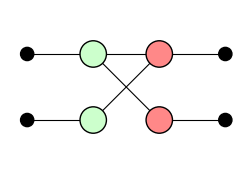

In [13]:
import pyzx as zx
zx.draw_matplotlib(p.logical_action(fine, 3).graph, figsize=(3, 2))

## Part F. Question 3: does it implement T in every run?

Now the whole injection as one block, the coarse level:

In [14]:
coarse_summary = p.summary(coarse)
print(coarse_summary.table())
print()
act = p.logical_action(coarse, 1)
print(act.describe())

block          role       code before  code after  logical action  every run?  checks
0 encode data  encoder    [[1,1,1]]    [[7,1,3]]   I               yes         ok
1 inject T     injection  [[7,1,3]]    [[7,1,3]]   T               yes         ok



logical action: 1 -> 1 logical qubit(s)
  when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 0 and c[7] + c[9] + c[6] = 0: T
  when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 1 and c[7] + c[9] + c[6] = 1: T
  deterministic: every run implements T


**T in every run.** How can the tool say "every run" when there are 2¹³ possible measurement results?

After simplification, the diagram depends on the outcomes only through a few **parities** written on its spiders. The tool tries every combination of values of those parities, each with a matching set of outcomes, and names what happens in each. That covers all runs.

Here there are two parities:

* `c[6] + ... + c[12]`: the readout parity that controls the correction;
* `c[6] + c[7] + c[9]`: the parity that decides between T and T† before the correction.

They look different but are always equal. The other four readouts, `c[8] + c[10] + c[11] + c[12]`, are the Z check on face 3 (qubits 2, 4, 5, 6 of the magic block), and stage 3 already measured that check as 0. The tool knows this from the detectors, so only two of the four combinations can happen. In both, the result is T.

The matrices of the two classes of runs:

In [15]:
Tm = np.diag([1, np.exp(1j * np.pi / 4)])
for b in act.branches():
    m = act.matrix(b.outcomes)
    m = m / m[0, 0]                                   # remove the global phase
    print(b.when(), "->", b.operation)
    print(np.round(m, 3)); print("equal to T:", np.allclose(m, Tm)); print()

when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 0 and c[7] + c[9] + c[6] = 0 -> T
[[1.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707+0.707j]]
equal to T: True

when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 1 and c[7] + c[9] + c[6] = 1 -> T
[[1.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707+0.707j]]
equal to T: True



## Part G. Four changes, and what the table says

The table is most useful when something is wrong. Each cell below changes one thing in the program.

### G.1 Forgetting the correction

In [16]:
p1 = injection_program(correction=None)
print(p1.logical_action().describe())

logical action: 1 -> 1 logical qubit(s)
  when c[7] + c[9] + c[6] = 0: T
  when c[7] + c[9] + c[6] = 1: T^dag
  not deterministic: the operation depends on the outcomes (T when c[7] + c[9] + c[6] = 0; T^dag when c[7] + c[9] + c[6] = 1)


Without the correction the program implements **T when c[6]+c[7]+c[9] is 0, and T† when it is 1**: half of the runs are wrong. The tool says "not deterministic" and names both cases.

### G.2 Using S instead of S†: looks wrong, is fine

S on all seven qubits is the logical **S†**, not S. So correcting with S everywhere looks like a mistake.

In [17]:
p2 = injection_program(correction='S')
print(p2.logical_action().describe())

logical action: 1 -> 1 logical qubit(s)
  when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 0 and c[7] + c[9] + c[6] = 0: T
  when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] + c[12] = 1 and c[7] + c[9] + c[6] = 1: T with correction Z
  deterministic up to a Pauli frame: every run implements T followed by a Pauli correction (Z, none) that the outcomes determine


The tool says it still works: every run gives T, and in the odd runs T is followed by a **Z**. Indeed S†·T† = Z·T. A Pauli such as Z does not need to be applied at all. The computer only has to remember it (the **Pauli frame**) and flip the meaning of later measurements. So this correction is fine, as long as the Z is tracked. The tool says which Pauli to track and in which runs.

### G.3 A correction that reads only six of the seven outcomes

In [18]:
p3 = injection_program(correction=None)
p3.add_circuit(stage([ParityControlled('S^dag', DATA[i], READOUT[:6]) for i in range(7)]), name='correct')
print(p3.logical_action().describe())

logical action: 1 -> 1 logical qubit(s)
  when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] = 0 and c[7] + c[9] + c[6] = 0: T
  when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] = 0 and c[7] + c[9] + c[6] = 1: T^dag
  when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] = 1 and c[7] + c[9] + c[6] = 0: T^dag with correction Z
  when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] = 1 and c[7] + c[9] + c[6] = 1: T
  not deterministic: the operation depends on the outcomes (T when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] = 0 and c[7] + c[9] + c[6] = 0; T^dag when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] = 0 and c[7] + c[9] + c[6] = 1; T^dag when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] = 1 and c[7] + c[9] + c[6] = 0; T when c[6] + c[7] + c[8] + c[9] + c[10] + c[11] = 1 and c[7] + c[9] + c[6] = 1)


A real bug: the correction is applied on the wrong runs half the time, so in some runs the result is T† instead of T. The tool lists the four classes of runs and says "not deterministic".

### G.4 A check wired to the wrong qubit

Now the first Z check is wired to qubits 0, 3, 4, **6** instead of 0, 3, 4, **5**: one CNOT goes to the wrong place. "Z on 0, 3, 4, 6" is not a stabilizer of the Steane code.

In [19]:
p4 = injection_program(z_check=(0, 3, 4, 6))
lv4 = p4.group_stages([(0, 0, 'encode data', 'encoder'), (1, 2, 'prepare magic', 'state preparation'),
                       (3, 3, 'check magic', 'syndrome extraction'), (4, 4, 'transversal CNOT', 'logical gate'),
                       (5, 5, 'read out magic', 'logical measurement'), (6, 6, 'correct', 'correction')])
s4 = p4.summary(lv4)
print(s4.table())
print()
print(s4.blocks[2].describe())
print()
print('the whole program:', p4.logical_action().verdict())

block               role                 code before            code after             logical action                                    every run?  checks
0 encode data       encoder              [[1,1,1]]              [[7,1,3]]              I                                                 yes         ok
1 prepare magic     state preparation    [[7,1,3]]              [[7,1,3]] + [[7,1,3]]  I on qubits 0-6 (x) prepares T|+> on qubits 7-13  yes         ok
2 check magic       syndrome extraction  [[7,1,3]] + [[7,1,3]]  [[7,1,3]] + [[7,1,1]]  I                                                 yes         1 problem(s)
3 transversal CNOT  logical gate         [[7,1,3]] + [[7,1,1]]  [[14,2,2]]             CNOT(0->1)                                        yes         ok
4 read out magic    logical measurement  [[14,2,2]]             [[7,1,1]]              not recognised                                    no          1 problem(s)
5 correct           correction           [[7,1,1]]              

This one is subtle, and it shows why question 1 matters on its own:

* The whole program **still implements T** in every run (up to a Pauli X to track). A noiseless simulation would find nothing wrong.
* But the table says the checking block does **not stay in the same code**. After it, the magic block is in a **[[7,1,1]]** code: distance 1 instead of 3. Measuring an operator that is not a stabilizer replaced part of the code, and now a single error on one qubit can change the logical state without any check noticing.

So the program is correct but no longer protected. Only the "which code" column catches that. The same kind of mistake is what the tool found in the circuit of the fold-transversal H case study, where one check had been wired to qubit 2 instead of qubit 4.

## Summary

| question | how the tool answered it | where in the paper |
|---|---|---|
| 1. which code? | `code_at`: cut the program, bring the diagram to normal form, read the stabilizers off its two layers | §4 and §5 |
| 2. what does a block do? | `logical_action`: ideal encoder, then the block, then ideal decoder, then simplify | §5 |
| 3. every run? | `verdict`: try every combination of the parities the simplified diagram depends on | §5 |

The table of Part E is `p.summary(level)`, the "level up" of the paper. Part G showed the three kinds of answer it gives: *wrong* (G.1, G.3), *right up to a Pauli frame* (G.2) and *right but unprotected* (G.4). The same calls work unchanged on the fold-transversal H protocol (`FoldTransversalHadamard.ipynb`).